In [74]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import seaborn as sns
from pathlib import Path

from utils import plot_spatial_kernel_hex
from utils.plotting import vector_to_kernel, plot_stats
from utils.spatial_RF import compute_kernel, all_input_kernels
from matplotlib.colors import TwoSlopeNorm,  Normalize

from utils import stats_ctype_pair
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 300

In [75]:
data_dir = Path('results/connectome')

edges       = pd.read_feather(data_dir / 'edgelist_OL_columnar_T4T5norm.feather')
nodes_df    = pd.read_feather(data_dir / 'nodes_OL_columnar_T4T5norm.feather')

# edges       = pd.read_feather(data_dir / 'edgelist_OL_columnar.feather')
# nodes_df    = pd.read_feather(data_dir / 'nodes_OL_columnar.feather')

print("Available celltypes")
print("Number: ", nodes_df['cell_type'].nunique())
print(nodes_df['cell_type'].unique())

Available celltypes
Number:  24
['C2' 'C3' 'L1' 'L2' 'L3' 'L5' 'Mi1' 'Mi4' 'Mi9' 'T1' 'Tm1' 'Tm2' 'Tm20'
 'Tm4' 'Tm9' 'T4a' 'T4b' 'T4c' 'T4d' 'T5a' 'T5b' 'T5c' 'T5d' 'CT1']


In [76]:
POST_TYPE = "T5b"   # or "T5b"
RADIUS    = 2
THRESHOLD = 0.5
MEAN_THRESH = 0.0

# Choose what each matrix entry should contain
VALUE_COL = "count"   # or "count" 



In [77]:
from sklearn.metrics.pairwise import cosine_similarity


mean_kernels, full_kernels, input_types = all_input_kernels(
    POST_TYPE,
    edges,
    radius=RADIUS,
    threshold=THRESHOLD,
    value_col=VALUE_COL,
)

def full_kernel_to_block(full, value_col="signed_count"):
    full = full.copy()

    full["offset"] = (
        full["dp"].astype(int).astype(str)
        + "_"
        + full["dq"].astype(int).astype(str)
    )

    block = (
        full
        .pivot_table(
            index="post",
            columns="offset",
            values=value_col,
            aggfunc="sum",
            fill_value=0,
        )
        .sort_index()
    )

    return block

blocks = {
    pre_type: full_kernel_to_block(full_kernels[pre_type], value_col=VALUE_COL)
    for pre_type in input_types
}
# blocks

Strong input types:  ['Tm2', 'Tm9', 'CT1', 'Tm1', 'Tm4', 'T5b']


In [78]:
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import CCA
import numpy as np

def direct_cca_pair(X, Y, n_cc=1, min_nonzero_frac=0.05, min_var=1e-8):
    # Align posts
    common_posts = X.index.intersection(Y.index)
    X = X.loc[common_posts]
    Y = Y.loc[common_posts]
    
    keep_X = ((X > 0).mean(axis=0) >= min_nonzero_frac) & (X.var(axis=0) > min_var)
    keep_Y = ((Y > 0).mean(axis=0) >= min_nonzero_frac) & (Y.var(axis=0) > min_var)


    # Remove zero-variance columns
    X = X.loc[:,keep_X]
    Y = Y.loc[:,keep_Y]

    # Xz = StandardScaler().fit_transform(X)
    # Yz = StandardScaler().fit_transform(Y)

    cca = CCA(n_components=n_cc, max_iter=5000, scale=False)
    # Xc, Yc = cca.fit_transform(Xz, Yz)
    Xc, Yc = cca.fit_transform(X, Y)
    
    corrs = np.array([
        np.corrcoef(Xc[:, i], Yc[:, i])[0, 1]
        for i in range(n_cc)
    ])

    x_weights = pd.DataFrame(
        cca.x_weights_,
        index=X.columns,
        columns=[f"CCA{i+1}" for i in range(n_cc)]
    )

    y_weights = pd.DataFrame(
        cca.y_weights_,
        index=Y.columns,
        columns=[f"CCA{i+1}" for i in range(n_cc)]
    )

    return {
        "corrs": corrs,
        "X_scores": Xc,
        "Y_scores": Yc,
        "x_weights": x_weights,
        "y_weights": y_weights,
        "posts": common_posts,
        "X_columns": X.columns,
        "Y_columns": Y.columns,
        "cca": cca,
    }


In [79]:
def direct_cca_permutation_test(X, Y, n_cc=1, n_perm=500, random_state=0):
    rng = np.random.default_rng(random_state)

    real = direct_cca_pair(X, Y, n_cc=n_cc)
    real_corr = real["corrs"][0]

    common_posts = X.index.intersection(Y.index)
    X0 = X.loc[common_posts]
    Y0 = Y.loc[common_posts]

    null_corrs = []
    for _ in range(n_perm):
        Y_perm = Y0.iloc[rng.permutation(len(Y0))].copy()
        Y_perm.index = Y0.index

        perm = direct_cca_pair(X0, Y_perm, n_cc=n_cc)
        null_corrs.append(perm["corrs"][0])
    
    null_corrs = np.array(null_corrs)

    p_value = (np.sum(null_corrs >= real_corr) + 1) / (len(null_corrs) + 1)

    return {
        "real": real,
        "real_corr": real_corr,
        "null_corrs": null_corrs,
        "p_value": p_value,
    }



In [80]:
from itertools import combinations
from tqdm.auto import tqdm
import pandas as pd
import numpy as np

def run_all_pairwise_cca(
    blocks,
    n_cc=1,
    n_perm=500,
    random_state=0,
    ):
    pair_results = {}
    rows = []

    for a, b in tqdm(list(combinations(blocks.keys(), 2)), desc="Pairwise CCA"):
        out = direct_cca_permutation_test(
            blocks[a],
            blocks[b],
            n_cc=n_cc,
            n_perm=n_perm,
            random_state=random_state,
        )

        pair_results[(a, b)] = out

        null_corrs = out["null_corrs"]
        null_mean = null_corrs.mean()
        null_std = null_corrs.std(ddof=1)

        real_corr = out["real_corr"]
        corr_minus_null = real_corr - null_mean

        z_score = (
            corr_minus_null / null_std
            if null_std > 0
            else np.nan
        )

        rows.append({
            "input_1": a,
            "input_2": b,
            "real_corr": real_corr,
            "null_mean": null_mean,
            "null_std": null_std,
            "corr_minus_null": corr_minus_null,
            "z_score": z_score,
            "p_value": out["p_value"],
            "n_posts": len(out["real"]["posts"]),
            "n_features_1": len(out["real"]["X_columns"]),
            "n_features_2": len(out["real"]["Y_columns"]),
        })

    summary = pd.DataFrame(rows)

    summary = summary.sort_values(
        "corr_minus_null",
        ascending=False
    ).reset_index(drop=True)

    return summary, pair_results

cca_summary, cca_results = run_all_pairwise_cca(
    blocks,
    n_cc=1,
    n_perm=500,
    random_state=0,
)

cca_summary

Pairwise CCA:   0%|          | 0/15 [00:00<?, ?it/s]

Pairwise CCA: 100%|██████████| 15/15 [02:52<00:00, 11.52s/it]


,input_1,input_2,real_corr,null_mean,null_std,corr_minus_null,z_score,p_value,n_posts,n_features_1,n_features_2
0,Tm2,Tm1,0.657087,0.143051,0.021585,0.514036,23.814365,0.001996,836,7,5
1,Tm2,CT1,0.593585,0.107005,0.023133,0.486580,21.034454,0.001996,836,7,2
2,Tm2,Tm9,0.600012,0.164757,0.021409,0.435254,20.330688,0.001996,836,7,8
3,Tm9,Tm1,0.532726,0.148067,0.019947,0.384660,19.284570,0.001996,836,8,5
4,Tm9,Tm4,0.451206,0.138652,0.019980,0.312554,15.643189,0.001996,836,8,4
5,Tm2,Tm4,0.391009,0.131907,0.020194,0.259102,12.830633,0.001996,836,7,4
6,Tm9,CT1,0.365215,0.115491,0.021604,0.249725,11.558927,0.001996,836,8,2
7,CT1,Tm1,0.337231,0.091007,0.021189,0.246225,11.620554,0.001996,836,2,5
8,CT1,Tm4,0.330720,0.086581,0.022865,0.244139,10.677596,0.001996,836,2,4
9,Tm9,T5b,0.391979,0.156152,0.018744,0.235827,12.581444,0.001996,836,8,6


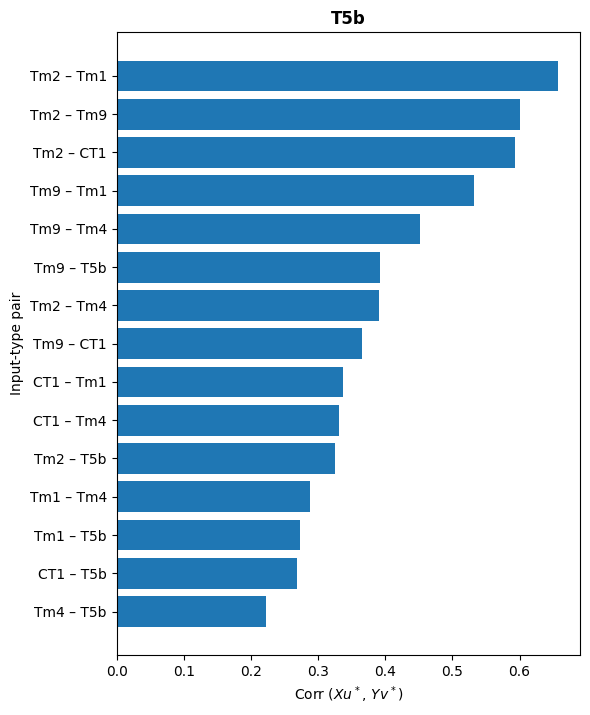

In [82]:
value_col = 'real_corr'
plot_df = cca_summary.sort_values(value_col, ascending=True).copy()
plot_df["pair"] = plot_df["input_1"] + " – " + plot_df["input_2"]

plt.figure(figsize=(6, 0.35 * len(plot_df) + 2))
plt.barh(plot_df["pair"], plot_df[value_col])
plt.xlabel(r"$\text{Corr }(Xu^*,\, Yv^*)$")
plt.ylabel("Input-type pair")
plt.title(f"{POST_TYPE}", fontweight='bold')
plt.tight_layout()
plt.show()

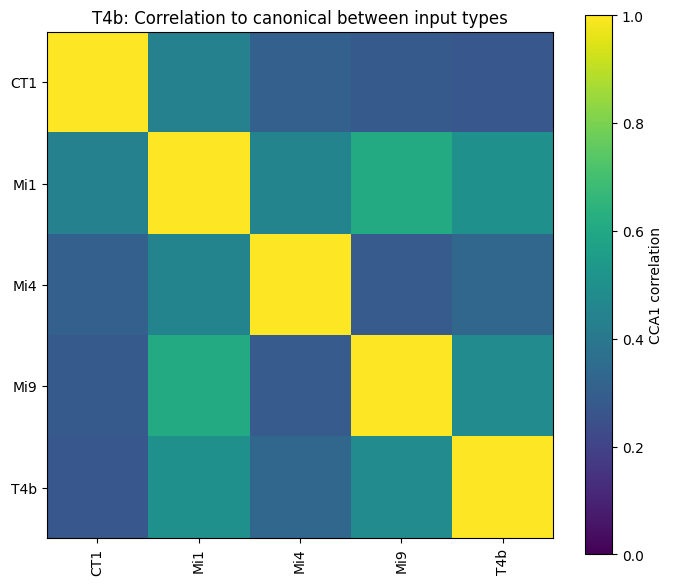

In [51]:
corr_mat = (
    cca_summary
    .pivot(index="input_1", columns="input_2", values="real_corr")
)

# Make symmetric matrix
all_types = sorted(set(cca_summary["input_1"]).union(cca_summary["input_2"]))
corr_sym = pd.DataFrame(np.nan, index=all_types, columns=all_types)

for _, row in cca_summary.iterrows():
    a = row["input_1"]
    b = row["input_2"]
    r = row["real_corr"]
    corr_sym.loc[a, b] = r
    corr_sym.loc[b, a] = r

np.fill_diagonal(corr_sym.values, 1.0)

plt.figure(figsize=(7, 6))
plt.imshow(corr_sym, vmin=0, vmax=np.nanmax(corr_sym.values))
plt.colorbar(label="CCA1 correlation")

plt.xticks(range(len(corr_sym.columns)), corr_sym.columns, rotation=90)
plt.yticks(range(len(corr_sym.index)), corr_sym.index)

plt.title(f"{POST_TYPE}: Correlation to canonical between input types")
plt.tight_layout()
plt.show()

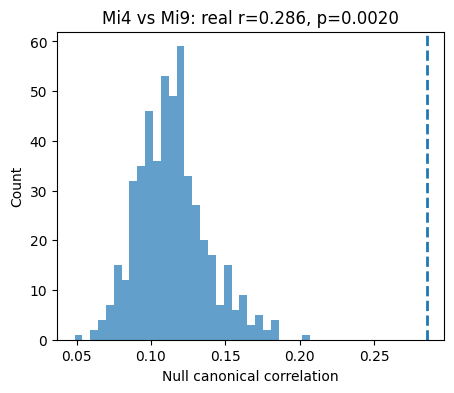

In [15]:
def get_pair_result(pair_results, a, b):
    if (a, b) in pair_results:
        return pair_results[(a, b)]
    elif (b, a) in pair_results:
        return pair_results[(b, a)]
    else:
        raise KeyError(f"No result for pair {a}, {b}")
    
def plot_cca_null(pair_results, a, b):
    out = get_pair_result(pair_results, a, b)

    plt.figure(figsize=(5, 4))
    plt.hist(out["null_corrs"], bins=30, alpha=0.7)
    plt.axvline(out["real_corr"], linestyle="--", linewidth=2)
    plt.xlabel("Null canonical correlation")
    plt.ylabel("Count")
    plt.title(f"{a} vs {b}: real r={out['real_corr']:.3f}, p={out['p_value']:.4f}")
    plt.show()
    
plot_cca_null(cca_results, "Mi4", "Mi9")

In [ ]:

all_full = []

for pre_type in input_types:
    full = full_kernels[pre_type].copy()

    full["pre_type"] = pre_type

    full["offset"] = (
        full["dp"].astype(int).astype(str)
        + "_"
        + full["dq"].astype(int).astype(str)
    )

    full["feature"] = (
        full["pre_type"].astype(str)
        + "__"
        + full["offset"].astype(str)
    )

    all_full.append(full)

all_full = pd.concat(all_full, ignore_index=True)


input_matrix = (
    all_full
    .pivot_table(
        index="post",
        columns="feature",
        values=VALUE_COL,
        aggfunc="sum",
        fill_value=0,
    )
    .rename_axis(columns=None)
)

In [11]:
input_matrix

,CT1__-1_-1,CT1__-1_-2,CT1__-1_0,CT1__-1_1,CT1__-2_-1,CT1__-2_-2,CT1__-2_0,CT1__0_-1,CT1__0_-2,CT1__0_0,...,Tm9__0_0,Tm9__0_1,Tm9__0_2,Tm9__1_-1,Tm9__1_0,Tm9__1_1,Tm9__1_2,Tm9__2_0,Tm9__2_1,Tm9__2_2
post,,,,,,,,,,,,,,,,,,,,,
80374,0.0,0.0,-20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,5.0,0.0,0.0,36.0,0.0,0.0,0.0,0.0,0.0
81491,0.0,0.0,-9.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,5.0,10.0,0.0,0.0,0.0,0.0,0.0
81721,0.0,0.0,-12.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,15.0,0.0,0.0,0.0,15.0,0.0,0.0,0.0,0.0,0.0
83167,0.0,0.0,-10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,6.0,0.0,0.0,0.0,7.0,0.0,0.0,0.0,0.0,0.0
83175,0.0,0.0,-17.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,7.0,0.0,0.0,0.0,17.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
206612,0.0,0.0,-14.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
220122,0.0,0.0,-7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
545103,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-7.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [12]:
# ------------------------------------------------------------
# Normalize each post cell's full input fingerprint
# ------------------------------------------------------------

total_input = input_matrix.abs().sum(axis=1) #Just in case we use signed_count

P = (
    input_matrix.loc[total_input > 0]
    .div(total_input.loc[total_input > 0], axis=0)
)

# ------------------------------------------------------------
# Pairwise cosine similarity between full input fingerprints
# ------------------------------------------------------------

sim = cosine_similarity(P)

i, j = np.triu_indices_from(sim, k=1)

sim_vals = sim[i, j]

posts = P.index.to_numpy()

post_i = posts[i]
post_j = posts[j]

sim_df = pd.DataFrame({
    "post_type": POST_TYPE,
    "input_set": "all_inputs",
    "post_i": post_i,
    "post_j": post_j,
    "cosine_similarity": sim_vals,
})

In [13]:
# ------------------------------------------------------------
# Cosine similarity to the mean full input fingerprint
# ------------------------------------------------------------

mean_P = P.mean(axis=0)

cosine_to_mean = cosine_similarity(
    P.values,
    mean_P.values.reshape(1, -1),
).ravel()

cosine_to_mean_df = pd.DataFrame({
    "post_type": POST_TYPE,
    "input_set": "all_inputs",
    "post": P.index,
    "cosine_similarity_to_mean": cosine_to_mean,
})

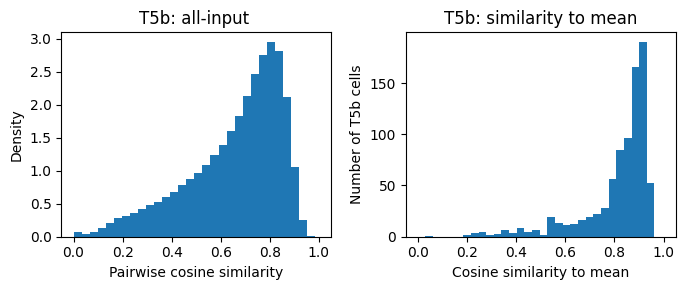

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3))

axes[0].hist(sim_vals, bins=30, density=True)
axes[0].set_xlabel("Pairwise cosine similarity")
axes[0].set_ylabel("Density")
axes[0].set_title(f"{POST_TYPE}: all-input ")

axes[1].hist(cosine_to_mean, bins=30)
axes[1].set_xlabel("Cosine similarity to mean")
axes[1].set_ylabel(f"Number of {POST_TYPE} cells")
axes[1].set_title(f"{POST_TYPE}: similarity to mean")

for ax in axes:
    ax.set_xlim(-0.05, 1.05)

fig.tight_layout()
plt.show()

In [15]:
# Use either all input types, or the thresholded/sorted input_types from above
types_to_include = input_types  # thresholded list
# types_to_include = list(kernels.keys())  # all presynaptic types
VALUE_COL = "mean_signed_count"
avg_rf = (
    pd.concat(
        [
            mean_kernels[pre_type][["dp", "dq", VALUE_COL]].assign(pre_cell_type=pre_type)
            for pre_type in types_to_include
        ],
        ignore_index=True
    )
    .groupby(["dp", "dq"], as_index=False)
    .agg(total_mean_signed_count=(VALUE_COL, "sum"))
)


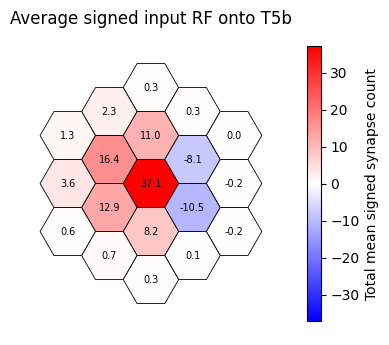

In [16]:

from matplotlib.colors import TwoSlopeNorm

rf_value_col = "total_mean_signed_count"

vmax = np.nanmax(np.abs(avg_rf[rf_value_col]))

norm = TwoSlopeNorm(
    vmin=-vmax,
    vcenter=0,
    vmax=vmax
)

fig, ax = plt.subplots(figsize=(4, 4))

plot_spatial_kernel_hex(
    avg_rf,
    value_col=rf_value_col,
    radius=2,
    cmap="bwr",
    norm=norm,
    ax=ax,
    title=f"Average signed input RF onto {POST_TYPE}",
    plot_labels=True,
    use_input_relative_to_target=True,
    mirror_x=True,
    mirror_y=True,
)

ax.axis("off")

sm = plt.cm.ScalarMappable(norm=norm, cmap=plt.get_cmap("bwr"))
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    shrink=0.75,
    label="Total mean signed synapse count"
)

plt.tight_layout()
plt.show()